# 10 - Error analysis

Out-of-fold predictions only. `residual = actual - predicted`, so a positive residual is an underprediction.

In [1]:
import json, sys, pathlib
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METRICS = ROOT / "evaluation" / "metrics"
PRED = ROOT / "evaluation" / "predictions"
PLOTS = ROOT / "evaluation" / "plots"
ERRORS = ROOT / "evaluation" / "error_analysis"

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def show(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except Exception:
        print("plot written to", path)


## Error summary per selected model

In [2]:
summary = pd.read_csv(ERRORS / "phase3_error_summary.csv")
summary[["configuration", "model", "n", "mae", "rmse", "bias", "n_overpredicted",
         "n_underpredicted", "p95_abs_error", "max_abs_error"]].round(3)

,configuration,model,n,mae,rmse,bias,n_overpredicted,n_underpredicted,p95_abs_error,max_abs_error
0,A_primary_640,svr_rbf,640,2.029,2.628,0.327,297,343,5.201,9.602
1,A_restricted_628,extra_trees,628,2.089,2.672,0.151,327,301,5.127,11.022
2,B_augmented_628,svr_rbf,628,1.725,2.268,0.141,322,306,4.399,11.591


## Where the errors are largest: states

In [3]:
by_state = pd.read_csv(ERRORS / "phase3_errors_by_state.csv")
by_state.sort_values("mae", ascending=False).groupby("configuration").head(8).round(3).to_string(index=False)

'                 state  n   mae   bias  max_abs_error    configuration       model\n           WEST BENGAL 19 5.368  5.368          9.586 A_restricted_628 extra_trees\n               TRIPURA  4 5.220 -5.220          7.389    A_primary_640     svr_rbf\n           WEST BENGAL 19 4.878  4.878          9.162    A_primary_640     svr_rbf\n                 ASSAM 27 4.809  4.798         11.022 A_restricted_628 extra_trees\n                 ASSAM 27 3.595  3.463          9.602    A_primary_640     svr_rbf\n                 ASSAM 27 3.433  3.090         11.591  B_augmented_628     svr_rbf\n                PUNJAB 20 3.391  3.391          6.939    A_primary_640     svr_rbf\nDADRA AND NAGAR HAVELI  1 2.882 -2.882          2.882 A_restricted_628 extra_trees\n            TAMIL NADU 32 2.792 -2.792          4.753    A_primary_640     svr_rbf\n              NAGALAND 11 2.788 -2.788          4.027 A_restricted_628 extra_trees\n     JAMMU AND KASHMIR 22 2.770 -2.661          5.347 A_restricted_628 extr

## By target band

Bias by band shows whether the model compresses the distribution: negative bias in the top band means extreme districts are underpredicted.

In [4]:
by_band = pd.read_csv(ERRORS / "phase3_errors_by_target_band.csv")
by_band.round(3).to_string(index=False)

'         band  n  mean_actual   mae   bias    configuration       model\n (0.199, 1.6] 66        1.183 2.443 -2.443    A_primary_640     svr_rbf\n   (1.6, 2.3] 65        2.012 2.072 -2.041    A_primary_640     svr_rbf\n   (2.3, 3.0] 64        2.745 1.296 -1.228    A_primary_640     svr_rbf\n   (3.0, 3.8] 68        3.460 1.218 -0.759    A_primary_640     svr_rbf\n   (3.8, 4.4] 59        4.151 1.170 -0.247    A_primary_640     svr_rbf\n   (4.4, 5.1] 63        4.806 1.267  0.200    A_primary_640     svr_rbf\n   (5.1, 5.9] 66        5.582 1.523  1.041    A_primary_640     svr_rbf\n   (5.9, 7.4] 62        6.689 1.693  1.508    A_primary_640     svr_rbf\n  (7.4, 9.11] 63        8.229 2.699  2.550    A_primary_640     svr_rbf\n (9.11, 17.7] 64       11.769 4.885  4.885    A_primary_640     svr_rbf\n(0.199, 1.67] 63        1.179 2.590 -2.590 A_restricted_628 extra_trees\n  (1.67, 2.3] 65        2.012 2.400 -2.400 A_restricted_628 extra_trees\n   (2.3, 3.0] 62        2.753 1.590 -1.570 A_restr

## Extreme districts versus the rest

In [5]:
extreme = pd.read_csv(ERRORS / "phase3_extreme_target_summary.csv")
extreme.round(3).to_string(index=False)

'           group   n  mean_actual   mae   bias  share_underpredicted    configuration       model\nextreme (top 5%)  35       13.231 5.863  5.863                 1.000    A_primary_640     svr_rbf\n       remainder 605        4.561 1.807  0.007                 0.509    A_primary_640     svr_rbf\nextreme (top 5%)  35       13.231 6.532  6.532                 1.000 A_restricted_628 extra_trees\n       remainder 593        4.576 1.827 -0.226                 0.449 A_restricted_628 extra_trees\nextreme (top 5%)  35       13.231 4.378  4.298                 0.971  B_augmented_628     svr_rbf\n       remainder 593        4.576 1.568 -0.104                 0.459  B_augmented_628     svr_rbf'

## Largest individual errors

In [6]:
largest = pd.read_csv(ERRORS / "phase3_largest_errors.csv")
largest.sort_values("abs_error", ascending=False).head(12).round(3).to_string(index=False)

'                         key       state        district  actual  predicted  residual  abs_error    configuration       model\n           ASSAM||HAILAKANDI       ASSAM      Hailakandi    16.1      4.509    11.591     11.591  B_augmented_628     svr_rbf\n              ASSAM||BARPETA       ASSAM         Barpeta    17.7      6.678    11.022     11.022 A_restricted_628 extra_trees\n              ASSAM||DARRANG       ASSAM         Darrang    17.2      6.886    10.314     10.314 A_restricted_628 extra_trees\n           ASSAM||HAILAKANDI       ASSAM      Hailakandi    16.1      5.930    10.170     10.170 A_restricted_628 extra_trees\n               ASSAM||DHUBRI       ASSAM          Dhubri    17.0      6.840    10.160     10.160 A_restricted_628 extra_trees\n               ASSAM||DHUBRI       ASSAM          Dhubri    17.0      7.398     9.602      9.602    A_primary_640     svr_rbf\nWEST BENGAL||PURBA MEDINIPUR WEST BENGAL Purba Medinipur    17.2      7.614     9.586      9.586 A_restricted_

## Diagnostic plots

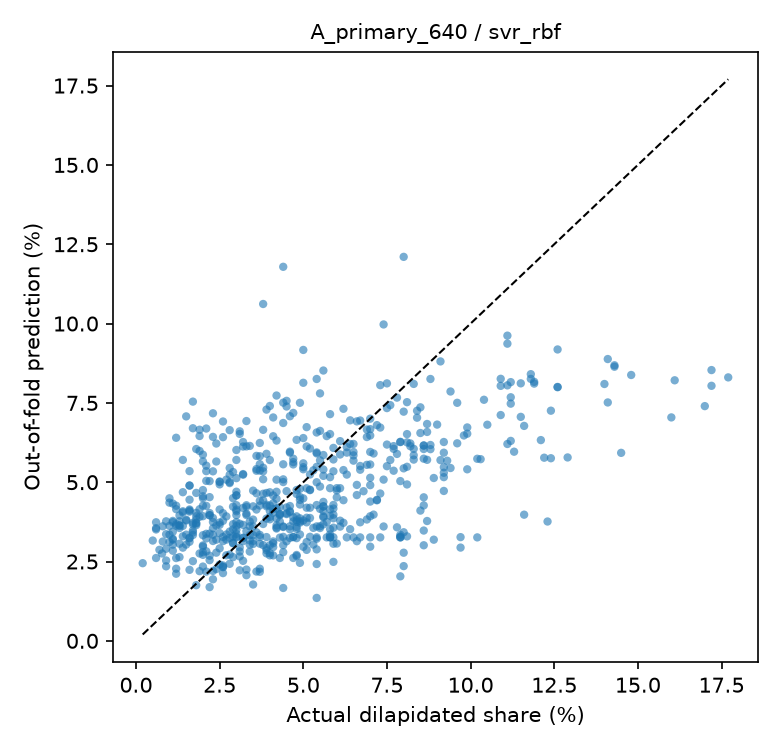

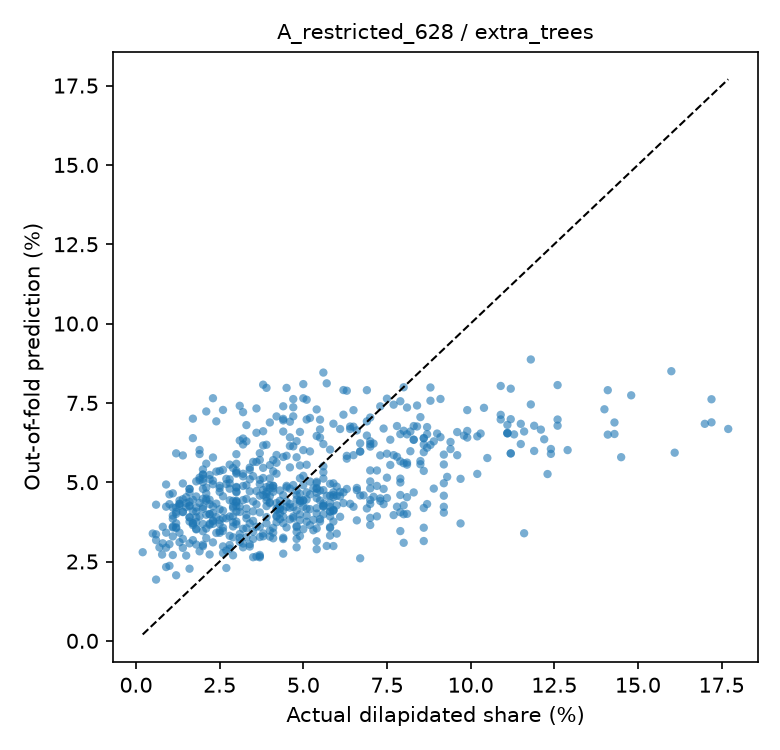

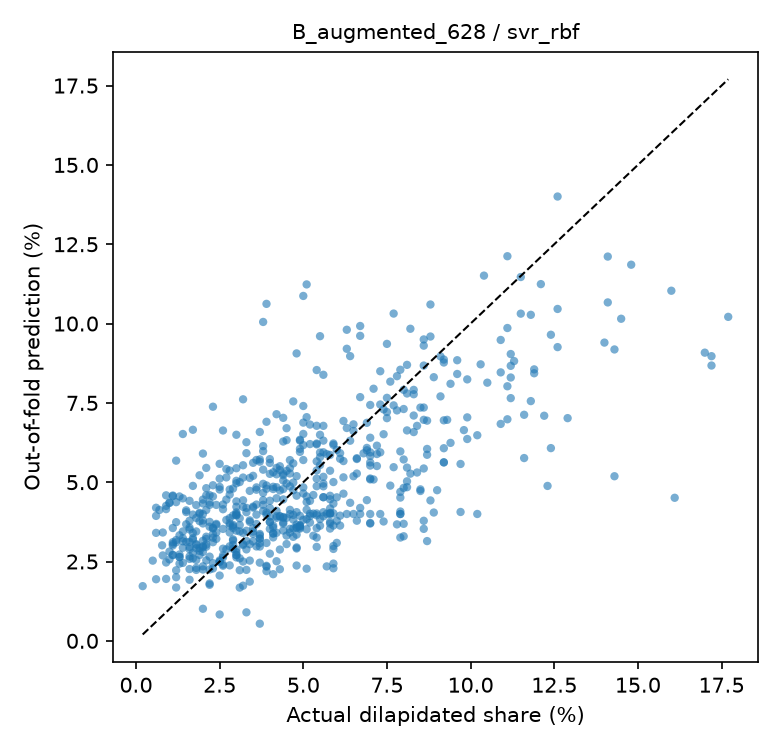

In [7]:
for suffix in ["a640", "a628", "b628"]:
    path = PLOTS / f"phase3_predicted_vs_actual_{suffix}.png"
    if path.exists():
        show(path)

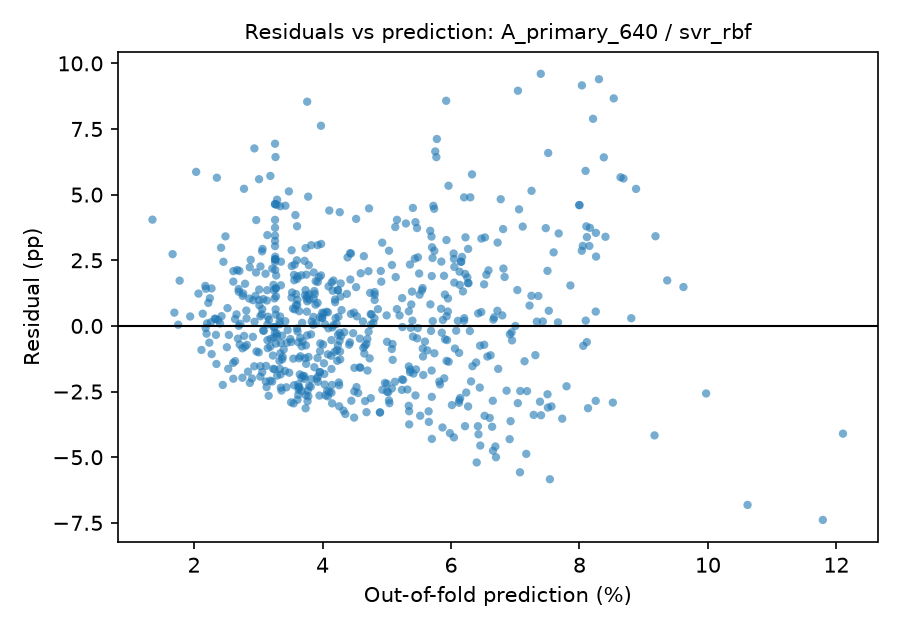

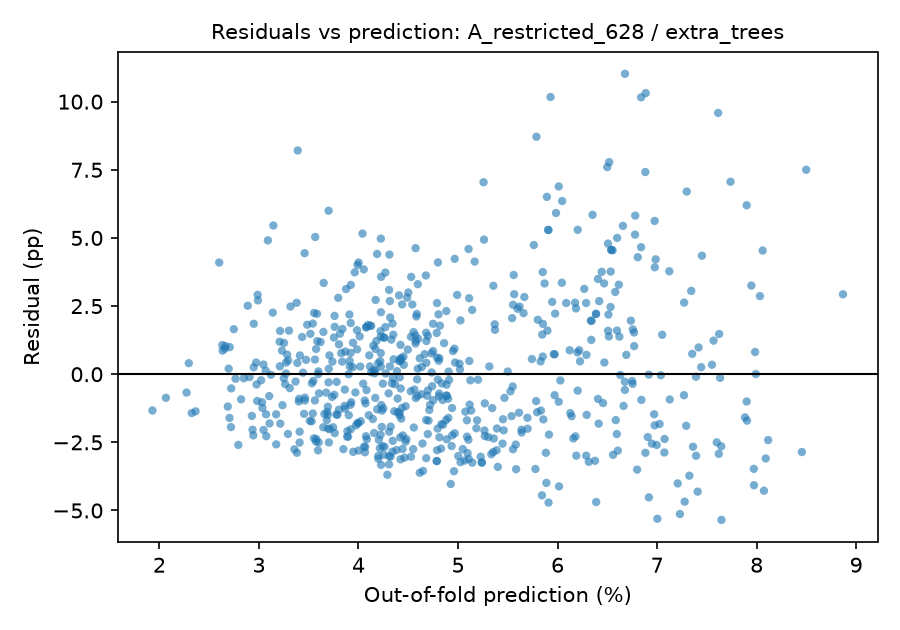

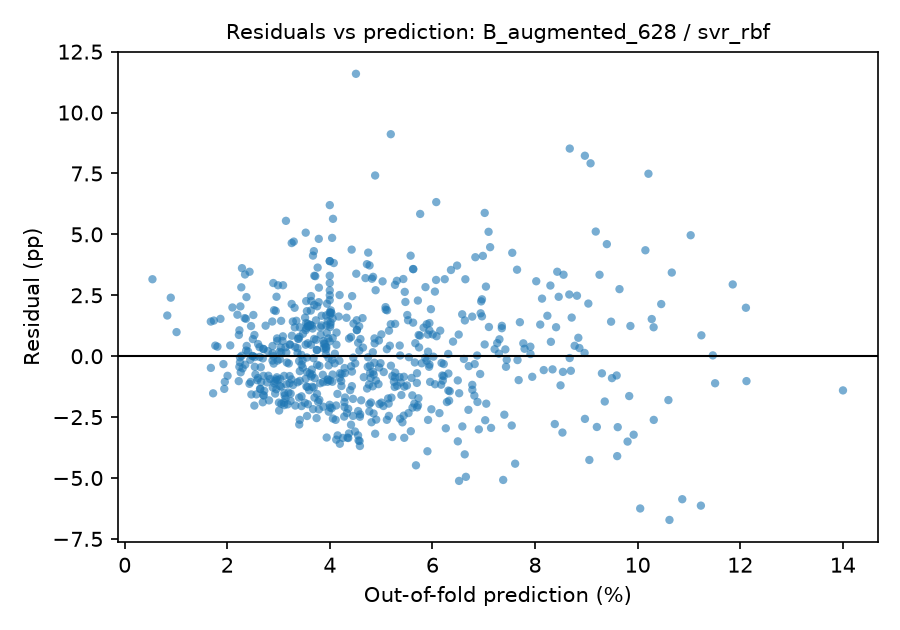

In [8]:
for suffix in ["a640", "a628", "b628"]:
    path = PLOTS / f"phase3_residuals_vs_predicted_{suffix}.png"
    if path.exists():
        show(path)

## Interpreting district-level errors

An individual district's prediction is not a validated risk ranking. These residuals locate where the model fails; they do not certify the districts it gets right.